In [1]:
import os
import sys

print("Python:", sys.executable)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))
print("MuJoCo path:", os.environ.get("MUJOCO_PY_MUJOCO_PATH"))
print("Renderer:", os.environ.get("MUJOCO_GL"))
print("PyOpenGL:", os.environ.get("PYOPENGL_PLATFORM"))

Python: /home/bannanakid/miniforge3/envs/rcrl/bin/python
LD_LIBRARY_PATH: /opt/ros/humble/opt/rviz_ogre_vendor/lib:/opt/ros/humble/opt/rviz_ogre_vendor/lib:/opt/ros/humble/lib/x86_64-linux-gnu:/opt/ros/humble/lib:/home/bannanakid/.mujoco/mujoco210/bin:/home/bannanakid/.mujoco/mujoco210/bin
MuJoCo path: /home/bannanakid/.mujoco/mujoco210
Renderer: osmesa
PyOpenGL: osmesa


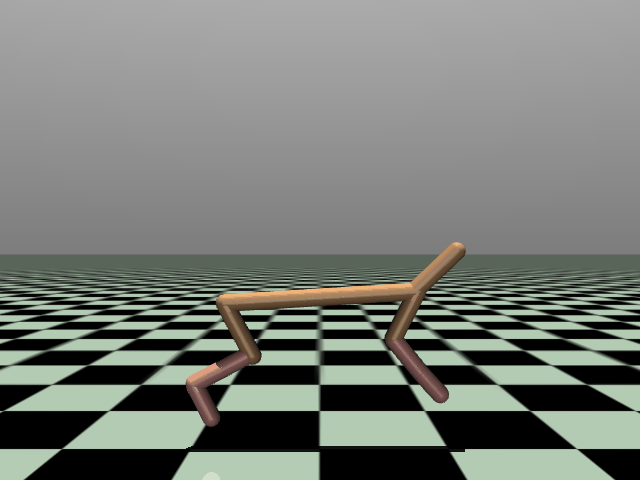

In [ ]:
import gymnasium as gym
import imageio.v2 as imageio
from IPython.display import Image, display

env = gym.make(
    "HalfCheetah-v4",
    render_mode="rgb_array",
    width=640,
    height=480,
)

observation, info = env.reset(seed=1)
frames = []

for step in range(300):
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)

    if step % 2 == 0:
        frame = env.render()
        if frame is not None:
            frames.append(frame)

    if terminated or truncated:
        observation, info = env.reset()

env.close()

if not frames:
    raise RuntimeError("No frames were produced.")

imageio.mimsave("half_cheetah_preview.gif", frames, fps=30)
display(Image(filename="half_cheetah_preview.gif"))

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path("/home/bannanakid/RCRL_on_RCMDP")
RUN_NUMBER = 1
SAFETY_THRESHOLD = 0.1

data_dir = (
    PROJECT
    / "data_train"
    / "HalfCheetahWithPos"
    / f"run{RUN_NUMBER}"
)

plot_dir = (
    PROJECT
    / "plot_data"
    / "HalfCheetahWithPos"
    / f"run{RUN_NUMBER}"
)

print("Data directory:", data_dir)
print("Plot directory:", plot_dir)

print("\nData files:")
for path in sorted(data_dir.glob("*")):
    print(" ", path.name)

print("\nPlot files:")
for path in sorted(plot_dir.glob("*")):
    print(" ", path.name)

Data directory: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahWithPos/run1
Plot directory: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahWithPos/run1

Data files:
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_1_GAMMA_0_costs.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_1_GAMMA_0_rewards.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_2_GAMMA_0_costs.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_2_GAMMA_0_rewards.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_3_GAMMA_0_costs.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_3_GAMMA_0_rewards.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_5_GAMMA_0_costs.npy
  RNAC_Gaussian_env_HalfCheetahWithPos_seed_5_GAMMA_0_rewards.npy
  evaluate_costs.npy
  evaluate_max_costs.npy
  evaluate_rewards.npy

Plot files:
  episode_max_costs.npy
  episode_rewards.npy
  eval_metrics.png
  training_metrics.png


In [2]:
evaluate_rewards = np.load(data_dir / "evaluate_rewards.npy")
evaluate_costs = np.load(data_dir / "evaluate_costs.npy")
evaluate_max_costs = np.load(data_dir / "evaluate_max_costs.npy")

metrics = {
    "Evaluation reward": evaluate_rewards,
    "Evaluation total cost": evaluate_costs,
    "Evaluation maximum cost": evaluate_max_costs,
}

for name, values in metrics.items():
    values = np.asarray(values).squeeze()

    print(f"\n{name}")
    print("  Shape:", values.shape)
    print("  Count:", values.size)
    print("  Mean:", float(np.mean(values)))
    print("  Standard deviation:", float(np.std(values)))
    print("  Minimum:", float(np.min(values)))
    print("  Maximum:", float(np.max(values)))
    print("  Final value:", float(values[-1]))


Evaluation reward
  Shape: (160,)
  Count: 160
  Mean: 2594.199189028336
  Standard deviation: 942.043098610463
  Minimum: -15.774260227909219
  Maximum: 3672.262802295679
  Final value: 3512.296116590627

Evaluation total cost
  Shape: (160,)
  Count: 160
  Mean: 16.48434801896413
  Standard deviation: 78.82532627190112
  Minimum: 0.0
  Maximum: 463.07367926836014
  Final value: 0.30575225750605267

Evaluation maximum cost
  Shape: (160,)
  Count: 160
  Mean: 0.11887063495814801
  Standard deviation: 0.09898170522359022
  Minimum: 0.0
  Maximum: 0.5
  Final value: 0.07040303945541382


In [ ]:
violations = evaluate_max_costs > SAFETY_THRESHOLD

print("Number of evaluation checkpoints:", len(evaluate_max_costs))
print("Violating checkpoints:", int(np.sum(violations)))
print(
    "Violation percentage:",
    float(np.mean(violations) * 100),
    "%"
)

safe_indices = np.where(~violations)[0]
violation_indices = np.where(violations)[0]

print("First safe checkpoints:", safe_indices[:10] + 1)
print("First violating checkpoints:", violation_indices[:10] + 1)


Evaluation reward
  Shape: (160,)
  Count: 160
  Mean: 2594.199189028336
  Standard deviation: 942.043098610463
  Minimum: -15.774260227909219
  Maximum: 3672.262802295679
  Final value: 3512.296116590627

Evaluation total cost
  Shape: (160,)
  Count: 160
  Mean: 16.48434801896413
  Standard deviation: 78.82532627190112
  Minimum: 0.0
  Maximum: 463.07367926836014
  Final value: 0.30575225750605267

Evaluation maximum cost
  Shape: (160,)
  Count: 160
  Mean: 0.11887063495814801
  Standard deviation: 0.09898170522359022
  Minimum: 0.0
  Maximum: 0.5
  Final value: 0.07040303945541382
